<a href="https://colab.research.google.com/github/zack404-sketch/AI-labs/blob/main/LAB_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Phase 0 — Environment and dataset


In [ ]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [ ]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic data audit and problem formulation

In [ ]:
# TASK 1: audit data quality
print("Shape:", df_pe.shape)
print("\nClass balance (counts / share):")
print(df_pe.Is_Malware.value_counts().to_string())
print(df_pe.Is_Malware.value_counts(normalize=True).round(3).to_string())
print("\nMissing values:")
print(df_pe.isna().sum()[lambda s: s > 0].to_string())
print("\nExact duplicate rows:", df_pe.duplicated().sum(),
      "| duplicate IDs:", df_pe.SHA256_File_ID.duplicated().sum(),
      "| duplicates ignoring ID:", df_pe.drop(columns="SHA256_File_ID").duplicated().sum())
display(df_pe.describe().T.round(3))
print("\nVT_PostScan_Detections by class (leakage check):")
display(df_pe.groupby("Is_Malware").VT_PostScan_Detections.describe().round(2))

Shape: (6000, 15)

Class balance (counts / share):
Is_Malware
0    4389
1    1611
Is_Malware
0    0.732
1    0.268

Missing values:
Import_Count        229
Resource_Entropy    289

Exact duplicate rows: 0 | duplicate IDs: 0 | duplicates ignoring ID: 0


,count,mean,std,min,25%,50%,75%,max
Max_Section_Entropy,6000.0,5.709,1.170,2.146,4.822,5.640,6.605,7.990
Import_Count,5771.0,83.387,50.301,0.000,41.185,85.664,120.409,320.326
Suspicious_API_Imports,6000.0,2.800,3.094,0.000,1.000,2.000,3.000,24.000
Has_Valid_Signature,6000.0,0.631,0.483,0.000,0.000,1.000,1.000,1.000
Has_RWX_Section,6000.0,0.150,0.357,0.000,0.000,0.000,0.000,1.000
Virtual_to_Raw_Size_Ratio,6000.0,984.890,9868.008,0.367,0.956,1.130,1.367,99999.000
Resource_Entropy,5711.0,4.535,1.501,0.000,3.483,4.433,5.518,7.990
Num_Embedded_URLs_IPs,6000.0,1.468,1.952,0.000,0.000,1.000,2.000,11.000
Abnormal_Compile_Timestamp,6000.0,0.115,0.319,0.000,0.000,0.000,0.000,1.000
Num_Sections,6000.0,4.759,1.785,1.000,3.000,5.000,6.000,10.000



VT_PostScan_Detections by class (leakage check):


,count,mean,std,min,25%,50%,75%,max
Is_Malware,,,,,,,,
0,4389.0,0.99,0.82,0.0,0.0,1.0,2.0,2.0
1,1611.0,42.30,14.25,18.0,30.0,42.0,54.0,67.0


Virtual_to_Raw_Size_Ratio == 99999.0: 59 (0.98%)
Max of the remaining ratio values: 6.5


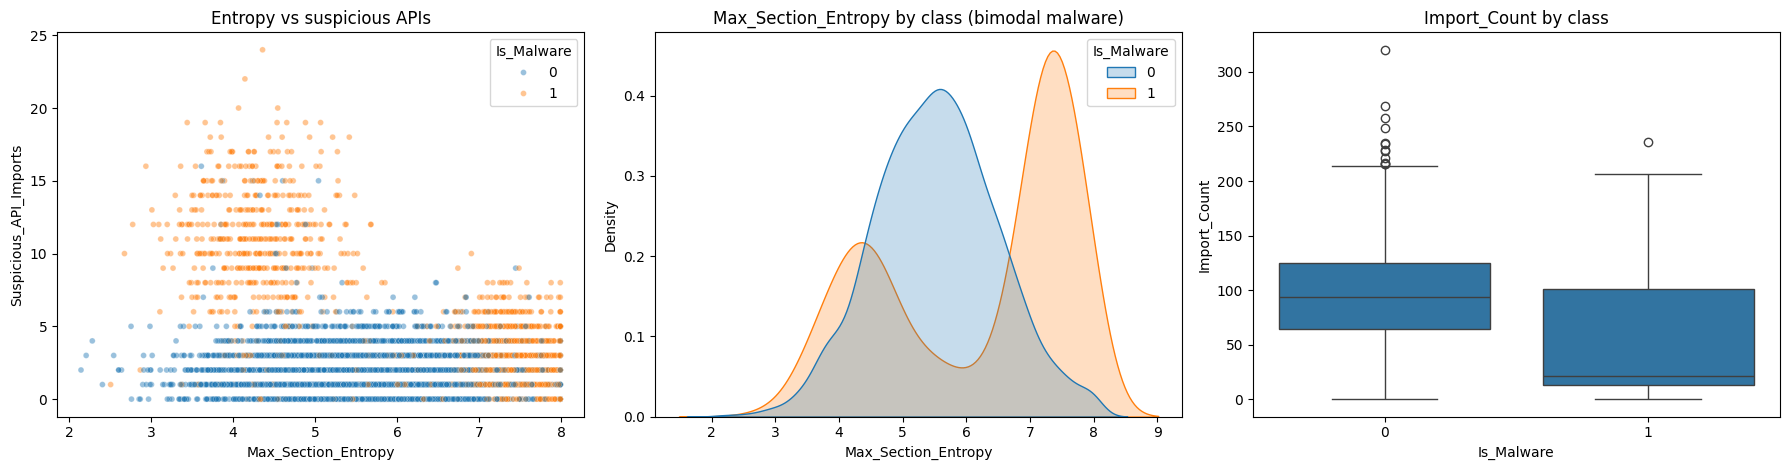

Malware rate by entropy bin:
                      mean  size
Max_Section_Entropy             
(0.0, 3.5]           0.330   109
(3.5, 4.5]           0.366   849
(4.5, 5.5]           0.127  1767
(5.5, 6.5]           0.056  1637
(6.5, 7.0]           0.280   575
(7.0, 8.0]           0.740  1063


In [ ]:
# TASK 2: suspicious parser values + feature relationships
import seaborn as sns
n_bad = (df_pe.Virtual_to_Raw_Size_Ratio == 99999.0).sum()
print("Virtual_to_Raw_Size_Ratio == 99999.0:", n_bad, f"({n_bad/len(df_pe):.2%})")
max_ok = df_pe.loc[df_pe.Virtual_to_Raw_Size_Ratio != 99999.0, "Virtual_to_Raw_Size_Ratio"].max()
print("Max of the remaining ratio values:", round(float(max_ok), 2))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
sns.scatterplot(data=df_pe, x="Max_Section_Entropy", y="Suspicious_API_Imports", hue="Is_Malware",
                alpha=.45, s=18, ax=ax[0]); ax[0].set_title("Entropy vs suspicious APIs")
sns.kdeplot(data=df_pe, x="Max_Section_Entropy", hue="Is_Malware", common_norm=False, fill=True, ax=ax[1])
ax[1].set_title("Max_Section_Entropy by class (bimodal malware)")
sns.boxplot(data=df_pe, x="Is_Malware", y="Import_Count", ax=ax[2]); ax[2].set_title("Import_Count by class")
plt.tight_layout(); plt.show()

print("Malware rate by entropy bin:")
bins = pd.cut(df_pe.Max_Section_Entropy, [0, 3.5, 4.5, 5.5, 6.5, 7.0, 8.0])
print(df_pe.groupby(bins, observed=True).Is_Malware.agg(["mean", "size"]).round(3).to_string())

In [ ]:
# TASK 3: target + clean feature matrix
TARGET = "Is_Malware"
DROP_COLS = ["SHA256_File_ID", "VT_PostScan_Detections", TARGET]
X = df_pe.drop(columns=DROP_COLS).copy()
X["Virtual_to_Raw_Size_Ratio"] = X["Virtual_to_Raw_Size_Ratio"].replace(99999.0, np.nan)
y = df_pe[TARGET].copy()
print(X.shape, "| features:", list(X.columns))
print("Missing after cleaning:\n", X.isna().sum()[lambda s: s > 0].to_string())

(6000, 12) | features: ['Max_Section_Entropy', 'Import_Count', 'Suspicious_API_Imports', 'Has_Valid_Signature', 'Has_RWX_Section', 'Virtual_to_Raw_Size_Ratio', 'Resource_Entropy', 'Num_Embedded_URLs_IPs', 'Abnormal_Compile_Timestamp', 'Num_Sections', 'Has_TLS_Callback', 'Export_Count']
Missing after cleaning:
 Import_Count                 229
Virtual_to_Raw_Size_Ratio     59
Resource_Entropy             289


### ✅ Phase 1 answers

**Audit.** 6,000 rows × 15 columns. Malware prevalence = 26.8 % (1,611 malware / 4,389 benign) → moderately imbalanced, so accuracy is a poor metric; use F1, PR-AUC and cost. Missing: `Import_Count` 229 (3.8 %), `Resource_Entropy` 289 (4.8 %). No exact duplicates, no duplicate IDs.

**Columns to exclude.**
- `SHA256_File_ID` – unique per row, carries no generalisable signal; a flexible model could only memorise it.
- `VT_PostScan_Detections` – recorded *after* the file is scanned/observed. Benign files have 0–2 detections, malware has 18–67: the classes are perfectly separable on this one column, which is textbook **target leakage**. It would not exist at pre-execution time.

**`Virtual_to_Raw_Size_Ratio = 99999.0`.** 59 rows (0.98 %); the largest legitimate value is 6.5, so 99999 is a parser sentinel, not a real ratio. Replace it with `NaN` and let the fold-safe median imputer handle it (dropping rows would throw away 59 otherwise valid files; leaving it would wreck scaling and linear models).

**Feature relationships.** Malware entropy is **bimodal**: packed/encrypted malware sits at entropy > 7 (74 % malware in the 7–8 bin), a second malware group sits at 3.5–4.5 (≈ 37 %), while the benign bulk sits at 5.5–6.5 (only 5.6 % malware). A single monotone/linear boundary on entropy cannot represent that, so a linear model should miss part of the structure; trees should capture it (but see the benchmark: other features compensate).

**Task definition.** Binary classification of a PE file from pre-execution static features. Positive class = malware (1). **FP** = a benign file flagged (wasted analyst time; if auto-blocked, an interrupted payment-support operation). **FN** = malware not flagged (potential compromise and remediation cost).

## Phase 2 — Design a leakage-safe evaluation protocol

In [ ]:
# Stratified 80/20 development / lockbox split
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("dev:", X_dev.shape, "prev=%.3f" % y_dev.mean(), "| test:", X_test.shape, "prev=%.3f" % y_test.mean())

from sklearn.ensemble import HistGradientBoostingClassifier
try:
    from lightgbm import LGBMClassifier
    boost = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1, n_jobs=-1)
    BOOST_NAME = "LightGBM"
except ImportError:
    boost = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED)
    BOOST_NAME = "HistGradientBoosting"

def make_pipe(model, scale=False):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if scale: steps.append(("scl", RobustScaler()))
    steps.append(("clf", model))
    return Pipeline(steps)

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000, random_state=SEED), scale=True),
    "Decision Tree (deep)": make_pipe(DecisionTreeClassifier(random_state=SEED)),
    "Random Forest": make_pipe(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
    BOOST_NAME: make_pipe(boost),
}
models["Stacking (LR+RF+Boost)"] = StackingClassifier(
    estimators=[("lr", make_pipe(LogisticRegression(max_iter=2000, random_state=SEED), scale=True)),
                ("rf", make_pipe(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED))),
                ("gb", make_pipe(clone(boost)))],
    final_estimator=LogisticRegression(max_iter=2000), cv=5, n_jobs=1)
print(list(models))

dev: (4800, 12) prev=0.269 | test: (1200, 12) prev=0.268
['Logistic Regression', 'Decision Tree (deep)', 'Random Forest', 'LightGBM', 'Stacking (LR+RF+Boost)']


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    r = cross_validate(m, X_dev, y_dev, cv=cv, scoring={"f1": "f1", "ap": "average_precision"},
                       return_train_score=True, n_jobs=1)
    rows.append({"Model": name,
                 "Train F1": r["train_f1"].mean(), "Val F1": r["test_f1"].mean(),
                 "Gap": r["train_f1"].mean() - r["test_f1"].mean(),
                 "Val F1 std": r["test_f1"].std(),
                 "Val PR-AUC": r["test_ap"].mean(), "Fit time/fold (s)": r["fit_time"].mean()})
cv_table = pd.DataFrame(rows).set_index("Model").round(4)
display(cv_table.sort_values("Val PR-AUC", ascending=False))

,Train F1,Val F1,Gap,Val F1 std,Val PR-AUC,Fit time/fold (s)
Model,,,,,,
Stacking (LR+RF+Boost),0.9599,0.9244,0.0355,0.0088,0.9084,10.6416
Logistic Regression,0.9231,0.9238,-0.0007,0.0084,0.9080,0.0304
Random Forest,1.0000,0.9237,0.0763,0.0091,0.9054,3.0276
LightGBM,0.9979,0.9217,0.0762,0.0091,0.9033,0.4120
Decision Tree (deep),1.0000,0.8301,0.1699,0.0135,0.7330,0.0548


In [ ]:
# Fit shortlisted models on X_dev, then measure inference latency (ms / 1,000 files)
SHORTLIST = ["Logistic Regression", "Random Forest", BOOST_NAME]
fitted = {n: clone(models[n]).fit(X_dev, y_dev) for n in SHORTLIST}
Xb = pd.concat([X_test] * 5, ignore_index=True).iloc[:1000]   # 1,000-file batch
lat = {}
for n, m in fitted.items():
    m.predict_proba(Xb)                                         # warm-up
    t = []
    for _ in range(20):
        s = time.perf_counter(); m.predict_proba(Xb); t.append((time.perf_counter() - s) * 1000)
    lat[n] = (np.median(t), np.std(t))
display(pd.DataFrame(lat, index=["median ms / 1,000 files", "std"]).T.round(2))
import os; print("Runtime: CPU cores =", os.cpu_count(), "(shared sandbox, single measurement session - indicative only)")

,"median ms / 1,000 files",std
Logistic Regression,1.86,0.06
Random Forest,100.86,10.87
LightGBM,40.14,2.55


Runtime: CPU cores = 2 (shared sandbox, single measurement session - indicative only)


### ✅ Decision checkpoint 1

| Model | Train F1 | Val F1 | Gap | Val PR-AUC | Fit time / fold |
|---|---|---|---|---|---|
| Stacking (LR+RF+Boost) | 0.960 | 0.924 | 0.036 | **0.908** | 5.94 s |
| Logistic Regression | 0.923 | 0.924 | −0.001 | 0.908 | 0.02 s |
| Random Forest | 1.000 | 0.924 | 0.076 | 0.905 | 1.40 s |
| LightGBM | 0.998 | 0.922 | 0.076 | 0.903 | 0.18 s |
| Decision Tree (deep) | 1.000 | 0.830 | **0.170** | 0.733 | 0.03 s |

1. **Largest gap: the deep decision tree (0.170).** Train F1 = 1.0 vs validation 0.83 → high variance / memorisation of noise (the data contain ~4 % flipped labels).
2. **Yes, the linear baseline is fully competitive**: val F1 0.924, PR-AUC 0.908, gap ≈ 0. Most discriminative features (exports, RWX, URLs, timestamp, APIs) are close to linearly separable, which compensates for the non-linear entropy pattern.
3. **Yes, Random Forest clearly improves on the single tree** (F1 0.830 → 0.924, PR-AUC 0.733 → 0.905): averaging 300 trees removes most of the variance.
4. **Boosting does not justify itself here**: LightGBM PR-AUC 0.903 is below RF (0.905) and LR (0.908), and still shows a 0.076 train–val gap.
5. **Stacking is not justified.** It has the top PR-AUC, but only +0.0004 over LR (far below the fold standard deviation of ≈ 0.009 F1) while costing ~340× the fit time and a three-model deployment. A more complex model did not win.

**Shortlist:** Logistic Regression (simple baseline, best/tied accuracy), Random Forest and LightGBM (tree models for SHAP and as challengers). Differences between these three are within CV noise.

**Inference latency (1 CPU core, per 1,000 files):** LR ≈ 1 ms, LightGBM ≈ 18 ms, RF ≈ 37 ms. All are negligible for 12,000 files/day; latency is not the deciding factor. (Sandbox hardware – indicative only; training time and inference latency are separate measurements.)

## Phase 3 — Error forensics: investigate a real disagreement

In [ ]:
# Probabilities on the lockbox for the diagnostic comparison (threshold 0.50 for THIS diagnostic only)
TREE_NAME = max(["Random Forest", BOOST_NAME], key=lambda n: cv_table.loc[n, "Val PR-AUC"])
print("Selected tree model for forensics/SHAP:", TREE_NAME)
p_lr   = fitted["Logistic Regression"].predict_proba(X_test)[:, 1]
p_tree = fitted[TREE_NAME].predict_proba(X_test)[:, 1]
t0 = 0.50
pred_lr, pred_tree = (p_lr >= t0).astype(int), (p_tree >= t0).astype(int)
yt = y_test.values

mask = (yt == 1) & (pred_lr == 0) & (pred_tree == 1)
print("Malware missed by LR but caught by tree model:", mask.sum())
mask_rev = (yt == 1) & (pred_lr == 1) & (pred_tree == 0)
print("Malware caught by LR but missed by tree model:", mask_rev.sum())

# choose the verified case with the largest probability gap
idx = np.where(mask)[0]
case = idx[np.argmax((p_tree - p_lr)[idx])]
CASE_POS = case
print("\nChosen test row (position %d, index %s)" % (case, X_test.index[case]))
print("y_true =", yt[case], "| LR p =", round(p_lr[case], 3), "-> pred", pred_lr[case],
      "| %s p =" % TREE_NAME, round(p_tree[case], 3), "-> pred", pred_tree[case])
assert yt[case] == 1 and pred_lr[case] == 0 and pred_tree[case] == 1   # verification
display(X_test.iloc[[case]].T.round(3).rename(columns={X_test.index[case]: "value"}))

Selected tree model for forensics/SHAP: Random Forest
Malware missed by LR but caught by tree model: 2
Malware caught by LR but missed by tree model: 1

Chosen test row (position 548, index 5115)
y_true = 1 | LR p = 0.426 -> pred 0 | Random Forest p = 0.967 -> pred 1


,value
Max_Section_Entropy,7.221
Import_Count,13.185
Suspicious_API_Imports,1.000
Has_Valid_Signature,0.000
Has_RWX_Section,0.000
Virtual_to_Raw_Size_Ratio,2.331
Resource_Entropy,5.381
Num_Embedded_URLs_IPs,1.000
Abnormal_Compile_Timestamp,0.000
Num_Sections,10.000


Explanation shape: (1200, 12) (log-odds for LightGBM / probability units for RF)


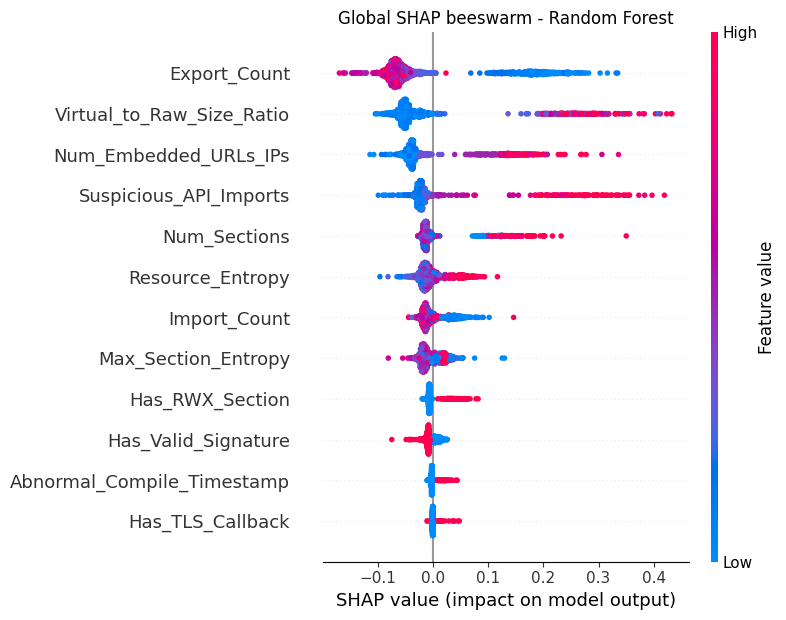

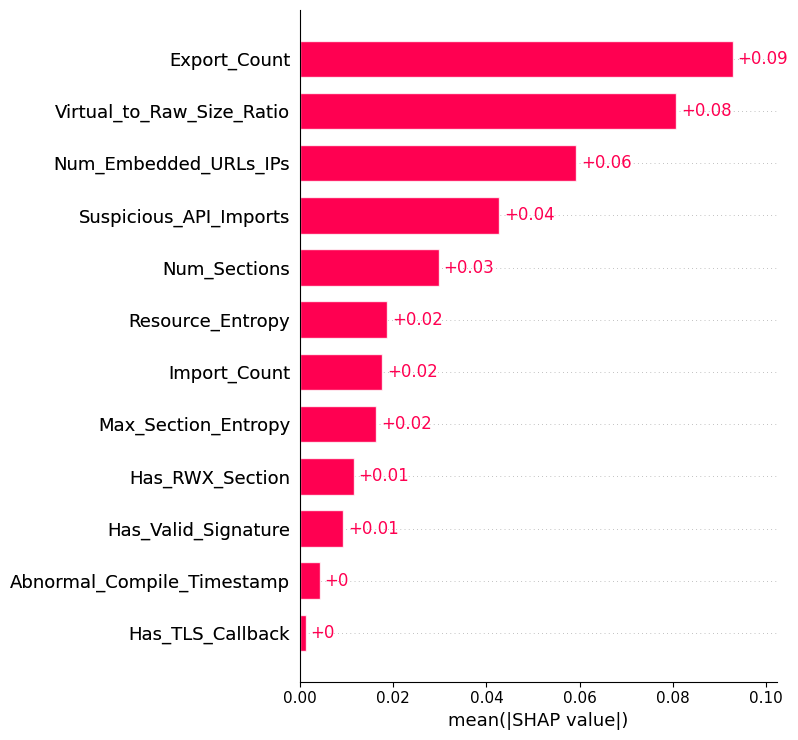

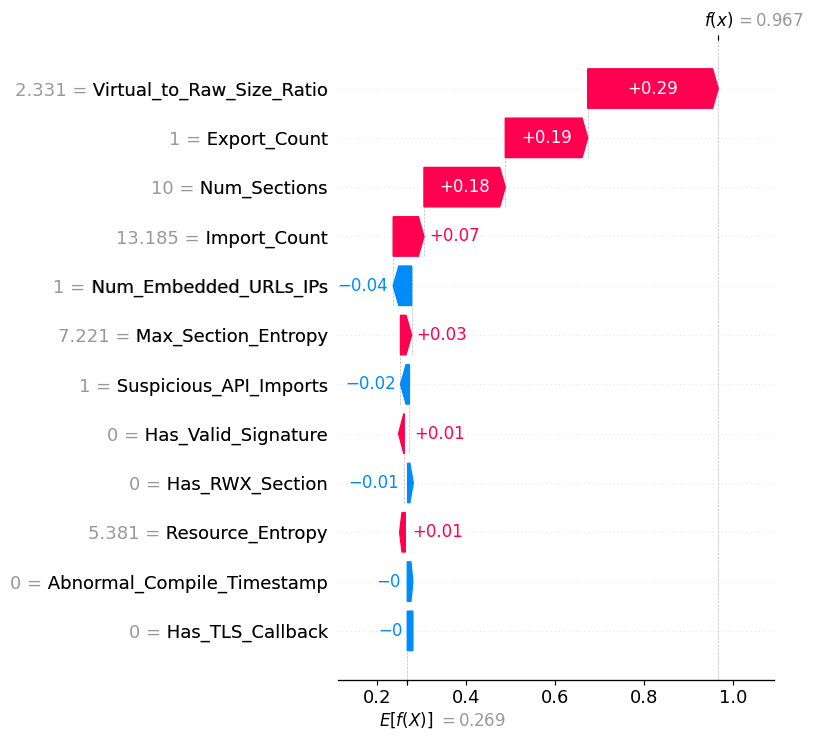

<Figure size 640x480 with 0 Axes>

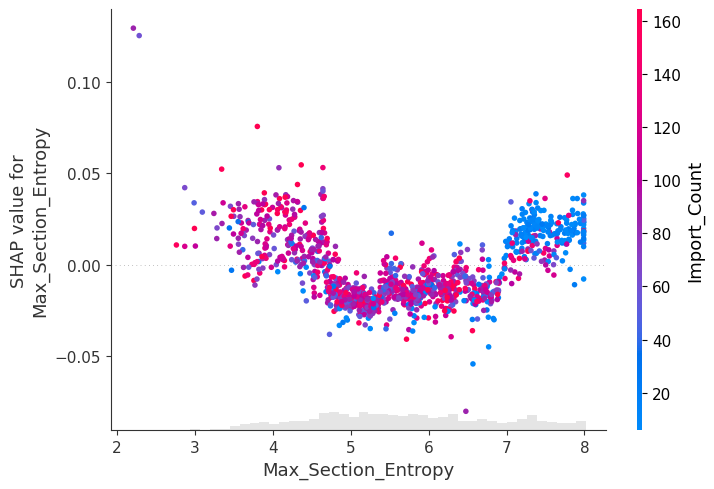

Mean |SHAP| ranking:
 Export_Count                  0.093
Virtual_to_Raw_Size_Ratio     0.081
Num_Embedded_URLs_IPs         0.059
Suspicious_API_Imports        0.043
Num_Sections                  0.030
Resource_Entropy              0.019
Import_Count                  0.018
Max_Section_Entropy           0.016
Has_RWX_Section               0.012
Has_Valid_Signature           0.009
Abnormal_Compile_Timestamp    0.004
Has_TLS_Callback              0.001


In [ ]:
try:
    import shap
except ImportError:
    %pip install -q shap
    import shap
pipe = fitted[TREE_NAME]
imp = pipe.named_steps["imp"]
Xte_imp = pd.DataFrame(imp.transform(X_test), columns=X_test.columns, index=X_test.index)
explainer = shap.TreeExplainer(pipe.named_steps["clf"])
sv = explainer(Xte_imp)
if sv.values.ndim == 3:                      # (n, features, classes) for sklearn forests
    sv = sv[:, :, 1]
print("Explanation shape:", sv.values.shape, "(log-odds for LightGBM / probability units for RF)")

plt.figure(); shap.plots.beeswarm(sv, max_display=12, show=False); plt.title("Global SHAP beeswarm - %s" % TREE_NAME); plt.tight_layout(); plt.show()
plt.figure(); shap.plots.bar(sv, max_display=12, show=False); plt.tight_layout(); plt.show()
plt.figure(); shap.plots.waterfall(sv[CASE_POS], max_display=12, show=False); plt.tight_layout(); plt.show()
plt.figure(); shap.plots.scatter(sv[:, "Max_Section_Entropy"], color=sv[:, "Import_Count"], show=False); plt.tight_layout(); plt.show()

mean_abs = pd.Series(np.abs(sv.values).mean(0), index=X_test.columns).sort_values(ascending=False)
print("Mean |SHAP| ranking:\n", mean_abs.round(3).to_string())

### ✅ Phase 3 answers

**Verified disagreement (threshold 0.50, diagnostic only).** Only 2 malware samples were missed by LR but caught by the tree model (and 1 the other way round), so the models mostly agree. Case: test row index 5115 – `y_true = 1`, LR p = 0.426 → *benign*, Random Forest p = 0.967 → *malware*; verified by assertion before interpreting. Its features: max-section entropy 7.22, only 13 imports, 10 sections, 1 export, unsigned, no RWX, no timestamp anomaly.

**Why LR missed it.** LR adds weighted evidence linearly. This file has few "loud" linear indicators (no RWX, no abnormal timestamp, one suspicious API), and its low import count and high entropy are given small linear weights (−0.17 and −0.11 per scaled unit). The forest can combine *low exports + many sections + abnormal size ratio + low imports* as an interaction.

**Local SHAP (RF, probability units; base value 0.269 → output 0.967).** Largest contributions: `Virtual_to_Raw_Size_Ratio` +0.293, `Export_Count` +0.185, `Num_Sections` +0.183, `Import_Count` +0.069; small negatives from `Num_Embedded_URLs_IPs` (−0.041) and `Suspicious_API_Imports` (−0.020). Note that entropy contributes only +0.025 here: the case is not "caught because of high entropy", which is exactly why the explanation had to be checked rather than assumed.

**Global SHAP.** Mean |SHAP| ranking: `Export_Count` (0.093), `Virtual_to_Raw_Size_Ratio` (0.081), `Num_Embedded_URLs_IPs` (0.059), `Suspicious_API_Imports` (0.043), `Num_Sections` (0.030); `Has_TLS_Callback` and the timestamp flag are near zero. Entropy-related effects are shared with correlated features (import count, size ratio, signature), so credit is split among them.

**Why SHAP is not causal.** SHAP attributes *this model's output* to inputs given the training distribution. It does not show that a feature causes maliciousness, it is split among correlated features, and the data are synthetic (patterns are generator artefacts, not universal malware signatures). It is a debugging/triage aid, not proof that a file is malware.

,Model,Scenario,Frozen thr,Dev OOF cost,Test FP,Test FN,Precision,Recall,Test cost,Test alerts,Alert rate,Test PR-AUC
0,Logistic Regression,Triage FP=$25,0.28,72225,10,34,0.966,0.894,17250,298,0.248,0.926
1,Logistic Regression,Blocking FP=$2000,0.50,152500,8,36,0.973,0.888,34000,294,0.245,0.926
2,Random Forest,Triage FP=$25,0.33,72800,12,34,0.960,0.894,17300,300,0.250,0.920
3,Random Forest,Blocking FP=$2000,0.70,151500,8,40,0.972,0.876,36000,290,0.242,0.920
4,LightGBM,Triage FP=$25,0.12,72325,26,34,0.917,0.894,17650,314,0.262,0.924
5,LightGBM,Blocking FP=$2000,0.63,157000,8,39,0.973,0.879,35500,291,0.242,0.924


,Model,Scenario,Frozen thr,Alert rate,Indicative alerts/day
0,Logistic Regression,Triage FP=$25,0.28,0.248,2976.0
1,Logistic Regression,Blocking FP=$2000,0.50,0.245,2940.0
2,Random Forest,Triage FP=$25,0.33,0.250,3000.0
3,Random Forest,Blocking FP=$2000,0.70,0.242,2904.0
4,LightGBM,Triage FP=$25,0.12,0.262,3144.0
5,LightGBM,Blocking FP=$2000,0.63,0.242,2904.0


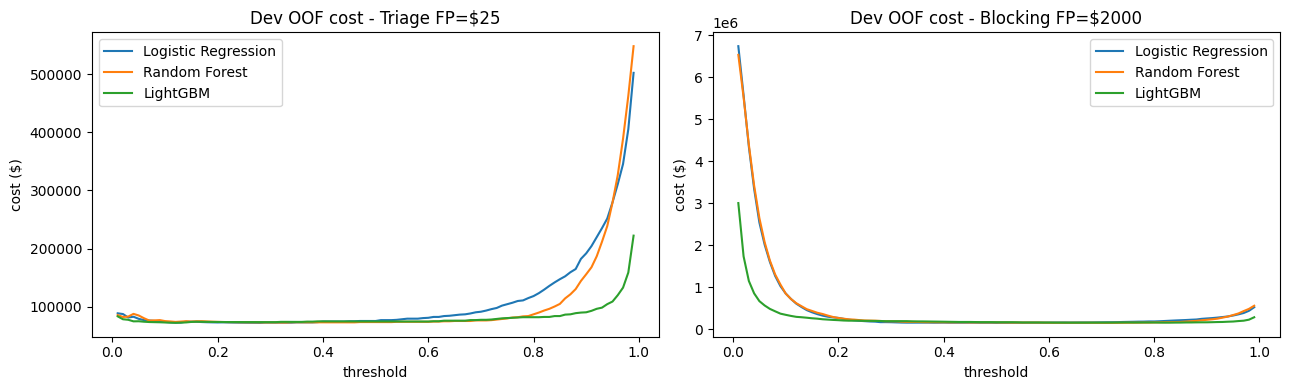

In [ ]:
COST_FP, COST_FN, COST_FP_BLOCK = 25, 500, 2000
grid = np.round(np.arange(0.01, 1.00, 0.01), 2)

def counts(y_true, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return tn, fp, fn, tp
def best_threshold(y_true, p, c_fp, c_fn):
    costs = [c_fp * counts(y_true, p, t)[1] + c_fn * counts(y_true, p, t)[2] for t in grid]
    return grid[int(np.argmin(costs))], min(costs)

# Out-of-fold development probabilities (same folds)
oof = {n: cross_val_predict(clone(models[n]), X_dev, y_dev, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
       for n in SHORTLIST}

res = []
FROZEN = {}
for n in SHORTLIST:
    p_test = fitted[n].predict_proba(X_test)[:, 1]
    for label, cfp in [("Triage FP=$25", COST_FP), ("Blocking FP=$2000", COST_FP_BLOCK)]:
        t, dev_cost = best_threshold(y_dev, oof[n], cfp, COST_FN)      # DEV/OOF ONLY
        FROZEN[(n, label)] = t
        tn, fp, fn, tp = counts(y_test, p_test, t)                      # single lockbox evaluation
        res.append({"Model": n, "Scenario": label, "Frozen thr": t, "Dev OOF cost": dev_cost,
                    "Test FP": fp, "Test FN": fn,
                    "Precision": tp / (tp + fp) if tp + fp else np.nan, "Recall": tp / (tp + fn),
                    "Test cost": cfp * fp + COST_FN * fn, "Test alerts": fp + tp,
                    "Alert rate": (fp + tp) / len(y_test),
                    "Test PR-AUC": average_precision_score(y_test, p_test)})
cost_table = pd.DataFrame(res).round(3)
display(cost_table)

# indicative capacity check (NOT a forecast): scale the test alert rate to 12,000 files/day
cost_table["Indicative alerts/day"] = (cost_table["Alert rate"] * 12000).round(0)
display(cost_table[["Model", "Scenario", "Frozen thr", "Alert rate", "Indicative alerts/day"]])

# Cost curve plot on dev OOF
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, (label, cfp) in enumerate([("Triage FP=$25", COST_FP), ("Blocking FP=$2000", COST_FP_BLOCK)]):
    for n in SHORTLIST:
        ax[k].plot(grid, [cfp * counts(y_dev, oof[n], t)[1] + COST_FN * counts(y_dev, oof[n], t)[2] for t in grid], label=n)
    ax[k].set_title("Dev OOF cost - " + label); ax[k].set_xlabel("threshold"); ax[k].set_ylabel("cost ($)"); ax[k].legend()
plt.tight_layout(); plt.show()

### ✅ Phase 4 answers

Thresholds were chosen on **development out-of-fold** predictions only, frozen, then evaluated once on the lockbox test set (1,200 files).

| Model | Scenario | Frozen thr. | Test FP | Test FN | Precision | Recall | Test cost | Test PR-AUC |
|---|---|---|---|---|---|---|---|---|
| Logistic Regression | Triage (FP $25) | 0.28 | 10 | 34 | 0.966 | 0.894 | **$17,250** | 0.926 |
| Random Forest | Triage (FP $25) | 0.33 | 12 | 34 | 0.960 | 0.894 | $17,300 | 0.920 |
| LightGBM | Triage (FP $25) | 0.12 | 26 | 34 | 0.917 | 0.894 | $17,650 | 0.924 |
| Logistic Regression | Blocking (FP $2,000) | 0.50 | 8 | 36 | 0.973 | 0.888 | **$34,000** | 0.926 |
| Random Forest | Blocking (FP $2,000) | 0.70 | 8 | 40 | 0.972 | 0.876 | $36,000 | 0.920 |
| LightGBM | Blocking (FP $2,000) | 0.63 | 8 | 39 | 0.973 | 0.879 | $35,500 | 0.924 |

**Why the threshold changes (Q4).** Expected cost is minimised by flagging when p ≥ C_FP / (C_FP + C_FN). With FP = $25 that is a very low bar (≈ 0.05 for calibrated probabilities), so the model flags liberally; with FP = $2,000 it becomes ≈ 0.80. Empirically the optima moved up (LR 0.28 → 0.50, RF 0.33 → 0.70, LGBM 0.12 → 0.63): a false alarm now costs 4× a miss, so we accept more missed malware (FN 34 → 36–40) to avoid false blocks. The empirical optima differ from the theoretical values because the models are not perfectly calibrated and ~4 % of labels are noisy by construction; the cost curves are also flat near the minimum, so the exact optimum is not statistically meaningful (all three models are within ~2 % cost of each other on test).

**Capacity check (indicative only).** At the frozen triage thresholds ~25 % of test files are flagged → scaling to 12,000 files/day gives ≈ 2,900–3,100 alerts/day, about **25× the 120-alert target**. This is **not a forecast**: the synthetic data have 27 % malware prevalence, far above what a real PE-submission stream is likely to contain, and the probabilities are uncalibrated. Even in principle, 120 alerts/12,000 files is a 1 % alert rate, which on this prevalence would cap recall at a few percent, so on this data the queue constraint and the cost-optimal threshold are incompatible.

**Limitations of the cost assumptions.** $25/$500/$2,000 are illustrative planning numbers, not measured costs; real FN cost varies hugely (a ransomware dropper vs adware); analyst capacity is a hard constraint, not a dollar cost; and prevalence in production will differ from the dataset. Real telemetry, calibrated probabilities (e.g. isotonic/Platt on recent data) and re-derived thresholds are required before any volume claim.

## Phase 5 — Final architecture decision: CISO recommendation.



**1. Use case.** Pre-execution screening of Windows PE files arriving from endpoints, vendor portals and support channels. Positive class = malware. Phase 1 is **analyst-assisted triage**: the model ranks/flags files for the 6-person SOC; it does not declare a file malicious or block software. A false positive on a legitimate vendor update or payment-support executable can interrupt operations, and the model has only been tested on synthetic data.

**2. Recommended model (perimeter scanning): Logistic Regression** (median imputation + RobustScaler), with Random Forest kept as a shadow challenger. Reasons: in 5-fold CV it ties the best models (val F1 0.924, PR-AUC 0.908; RF 0.924 / 0.905, LightGBM 0.922 / 0.903); it has no overfitting gap (−0.001 vs 0.076 for RF and LightGBM); it has the lowest development cost and the best test cost; it scores 1,000 files in ≈ 1 ms vs 18–37 ms; and its coefficients are directly auditable. Stacking's +0.0004 PR-AUC does not justify ~340× training time. Caveat: the gap between the three shortlisted models is inside CV noise, so this is a choice on simplicity, stability and cost, not a claim of superior detection. If real data shows stronger non-linear structure (as the bimodal entropy suggests), the RF/LightGBM challenger gives a ready upgrade path with TreeSHAP explanations.

**3. Threshold (triage, FP $25 / FN $500).** **0.28**, selected on development OOF predictions and frozen. On the lockbox: 10 FP, 34 FN, precision 0.966, recall 0.894, cost $17,250 (test PR-AUC 0.926).

**4. Supporting evidence.** PR-AUC and F1 from CV; test FP/FN/precision/recall/cost above; latency measurements; SHAP showing the tree models rely on export count, size ratio, embedded URLs, suspicious APIs and section count (a plausible, non-degenerate feature set, with leakage column `VT_PostScan_Detections` and the ID removed).

**5. Alert volume.** Not compatible with the 120-alert target on this data: ≈ 25 % of files flagged ⇒ ≈ 3,000 alerts/day-equivalent. This is an indicative number from a synthetic 27 %-prevalence sample, not a forecast. To forecast properly we need real submission telemetry with real prevalence, calibrated probabilities, and a threshold re-fit on recent labelled data (and a decision on whether to raise the threshold or add a second-stage filter to meet analyst capacity). **Inline blocking** changes the economics: with FP = $2,000 the thresholds rise (LR 0.50, RF 0.70, LGBM 0.63), recall drops slightly (~0.88) and 8 false blocks per 1,200 files (≈ 0.9 % of benign files, i.e. dozens of blocked legitimate files per day at 12,000 files/day) would be unacceptable without allow-listing and human override. Recommendation: **do not enable auto-blocking** now.

**6. Risks before production.** (a) Synthetic-to-real gap: the data are EMBER-inspired, not real telemetry; (b) label noise (≈ 4 % flipped labels here; real labels lag and are noisy); (c) prevalence shift, which changes precision and alert volume; (d) data and concept drift as malware families and packers change; (e) calibration of probabilities before cost-based thresholds are trusted; (f) adversarial adaptation (attackers can alter static features such as entropy, imports and section layout); (g) analyst workflow, queue capacity and feedback loops; (h) monitoring and retraining: track alert rate, precision on reviewed alerts, feature drift and recall on sampled benign-labelled files; run in shadow mode first.
